In [1]:
import os
# This line for the Windows
os.add_dll_directory(r"C:\Users\PC\Desktop\openslide-win64-20230414\openslide-win64-20230414\bin")
import datastructure.dataset as dataset
import arguments.setting as setting

In [2]:
data_directories = ["../hamamatsu"]
working_directory = "../workdir/"
csv_file = "../patients.csv"
qupath_project_file = "../qupath_project/project.qpproj"
s = setting.Setting(data_directories, csv_file, working_directory, qupath_project_file)
data = dataset.Dataset(s)

Initial 1560 patients
Resulting in 21 patients
Resulting in 21 patients
Resulting in 21 patients
Resulting in 21 patients


In [3]:
required_wsis = []

In [7]:
for patient in data.get_test_set()[0]:
    for wsi in patient.get_wsis()[0]:
        required_wsis.append(wsi.file_name)

In [8]:
print("\n".join(required_wsis), file = open("required_wsis.txt", "w"))

In [16]:
total_tiles = 0
for patient in data.train_set[0]:
    patient.load_wsis()
    for wsi in patient.get_wsis()[0]:
        total_tiles += len(wsi.tiles[0])
print(total_tiles)

66291


In [3]:
import numpy as np

def min_max_image(img):
    img_min = np.min(img, axis = (0, 1))
    img_max = np.max(img, axis = (0, 1))
    return (img - img_min) / (img_max - img_min)

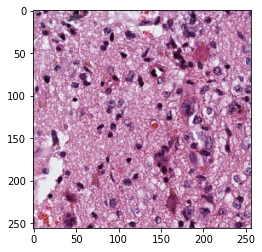

In [4]:
import matplotlib.pyplot as plt

patient = data.get_test_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()
plt.imshow(min_max_image(wsi.tiles[0][0].get_image(wsi.image)))

In [5]:
project = wsi.get_qupath_project()

In [7]:
project._inverse_class_dict

{'Tumor': 0,
 'Hirnparenchym': 1,
 'Infiltrationszone': 2,
 'Blutung': 3,
 'Luftblasen': 4,
 'Haare': 5,
 'Falten': 6,
 'Risse': 7,
 'Nekrosen': 8,
 'Pseudopalisaden': 9,
 'Artefakt': 10,
 'artifiziell verändertes Gewebe': 11,
 'Nekrose und Blutung': 12,
 'Pränekrose': 13,
 'out of focus': 14,
 'Filzstift': 15,
 'Unsicher': 16}

In [8]:
project.images[2].downsample_levels

[{'downsample': 1.0, 'width': 130560, 'height': 105984},
 {'downsample': 2.0, 'width': 65280, 'height': 52992},
 {'downsample': 4.0, 'width': 32640, 'height': 26496},
 {'downsample': 8.0, 'width': 16320, 'height': 13248},
 {'downsample': 16.0, 'width': 8160, 'height': 6624},
 {'downsample': 32.0, 'width': 4080, 'height': 3312},
 {'downsample': 64.0, 'width': 2040, 'height': 1656},
 {'downsample': 128.0, 'width': 1020, 'height': 828},
 {'downsample': 256.0, 'width': 510, 'height': 414}]

C:\Users\PC\AppData\Local\Programs\Python\Python39\lib\site-packages\tiffslide\tiffslide.py:750: UserWarning: hamamatsu-format metadata parsing only partially implemented!
  return getattr(self, f"parse_{fmt}")()  # type: ignore


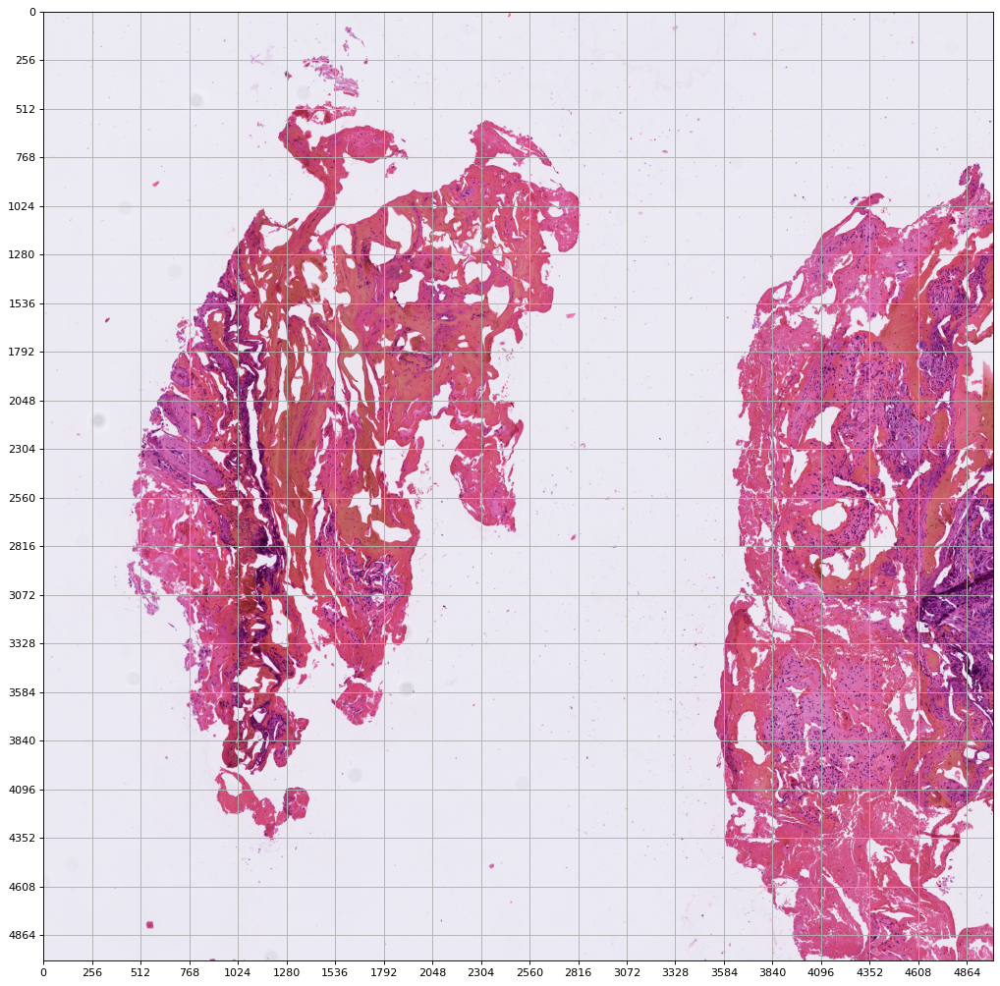

In [9]:
plt.figure(figsize=(16, 16), dpi=80)
major_ticks = np.arange(0, 5000, 256)
plt.xticks(major_ticks)
plt.yticks(major_ticks)
arr = project.get_tile(2, (32640 / 8 + 7000, 26496 / 8 + 9000), (5000, 5000), 2, ret_array = True)
plt.grid(which='both')
plt.imshow(arr)
plt.savefig("example_patches.png")

In [10]:
from histomicstk.preprocessing.color_normalization import reinhard
from histomicstk.saliency.tissue_detection import (
    get_slide_thumbnail, get_tissue_mask)

In [11]:
n_classes = len(wsi.qupath_project.path_classes) - 1

for index, c in enumerate(wsi.qupath_project.path_classes[:-1]):
    print(f"Class {c.name} returned as the channel {(index - 1 - n_classes) % n_classes} in MOTHI")

Class Tumor returned as the channel 15 in MOTHI
Class Hirnparenchym returned as the channel 0 in MOTHI
Class Infiltrationszone returned as the channel 1 in MOTHI
Class Blutung returned as the channel 2 in MOTHI
Class Luftblasen returned as the channel 3 in MOTHI
Class Haare returned as the channel 4 in MOTHI
Class Falten returned as the channel 5 in MOTHI
Class Risse returned as the channel 6 in MOTHI
Class Nekrosen returned as the channel 7 in MOTHI
Class Pseudopalisaden returned as the channel 8 in MOTHI
Class Artefakt returned as the channel 9 in MOTHI
Class artifiziell verändertes Gewebe returned as the channel 10 in MOTHI
Class Nekrose und Blutung returned as the channel 11 in MOTHI
Class Pränekrose returned as the channel 12 in MOTHI
Class out of focus returned as the channel 13 in MOTHI
Class Filzstift returned as the channel 14 in MOTHI


ImageEntries(['B7-18_HE_Hamamatsu_40x.ndpi', 'B9-18_HE_Hamamatsu_40x.ndpi', 'B11-18_HE_Hamamatsu_40x.ndpi', 'B17-19_HE_Hamamatsu_40x.ndpi', 'B20-16_HE_Hamamatsu_40x.ndpi', 'B27-19_HE_Hamamatsu_40x.ndpi', 'B30-18_HE_Hamamatsu_40x.ndpi', 'B35-18_1_HE_Hamamatsu_40x.ndpi', 'B35-18_2_HE_Hamamatsu_40x.ndpi', 'B36-17_1_HE_Hamamatsu_40x.ndpi', 'B36-17_2_HE_Hamamatsu_40x.ndpi', 'B37-17_HE_Hamamatsu_40x.ndpi', 'B42-17_HE_Hamamatsu_40x.ndpi', 'B68-18_HE_Hamamatsu_40x.ndpi', 'B85-17_HE_Hamamatsu_40x.ndpi', 'B100-17_HE_Hamamatsu_40x.ndpi', 'B115-17_HE_Hamamatsu_40x.ndpi', 'B127-19_HE_Hamamatsu_40x.ndpi', 'B128-19_HE_Hamamatsu_40x.ndpi', 'B129-19_HE_Hamamatsu_40x.ndpi', 'B132-17_HE_Hamamatsu_40x.ndpi', 'B138-18_HE_Hamamatsu_40x.ndpi', 'B149-16_HE_Hamamatsu_40x.ndpi', 'B157-17_HE_Hamamatsu_40x.ndpi', 'B162-17_HE_Hamamatsu_40x.ndpi', 'B165-19_HE_Hamamatsu_40x.ndpi', 'B177-18_HE_Hamamatsu_40x.ndpi', 'B178-19_HE_Hamamatsu_40x.ndpi', 'B179-17_HE_Hamamatsu_40x.ndpi', 'B181-16_HE_Hamamatsu_40x.ndpi', 'B187-16_HE_Hamamatsu_40x.ndpi', 'B201-18_HE_Hamamatsu_40x.ndpi', 'B205-09_HE_Hamamatsu_40x.ndpi', 'B205-18_1_HE_Hamamatsu_40x.ndpi', 'B205-18_2_HE_Hamamatsu_40x.ndpi', 'B205-18_HE_Hamamatsu_40x.ndpi', 'B23-18_HE_Hamamatsu_40x-006.ndpi'])
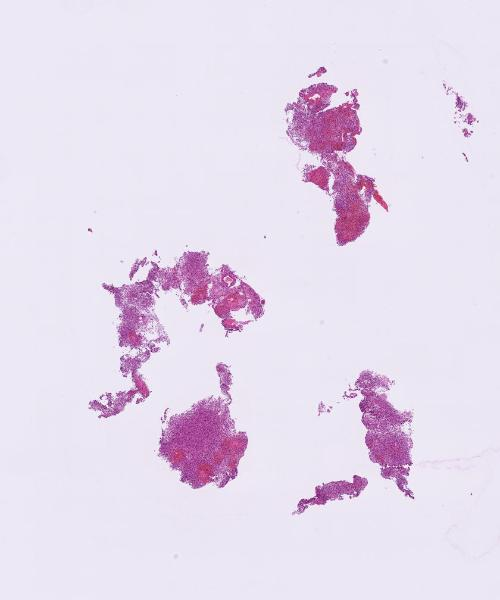
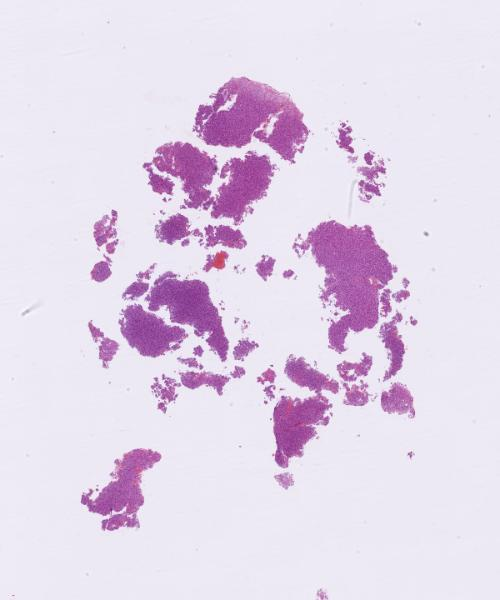
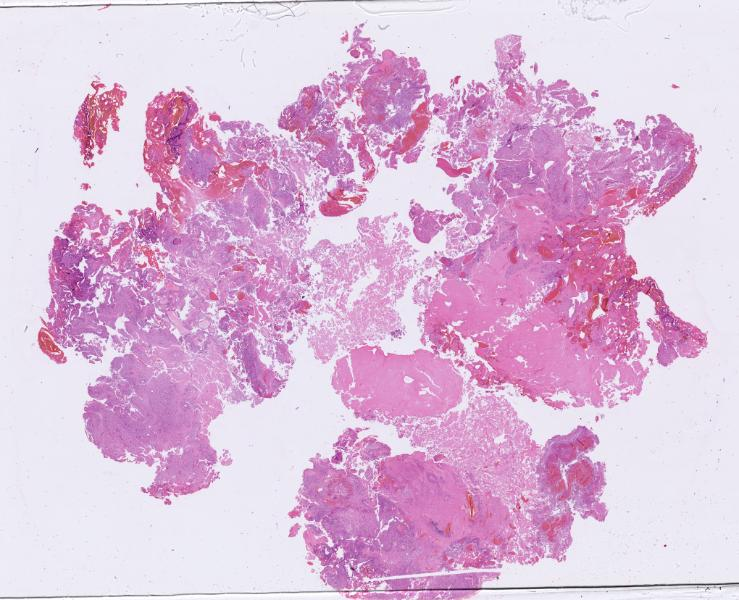
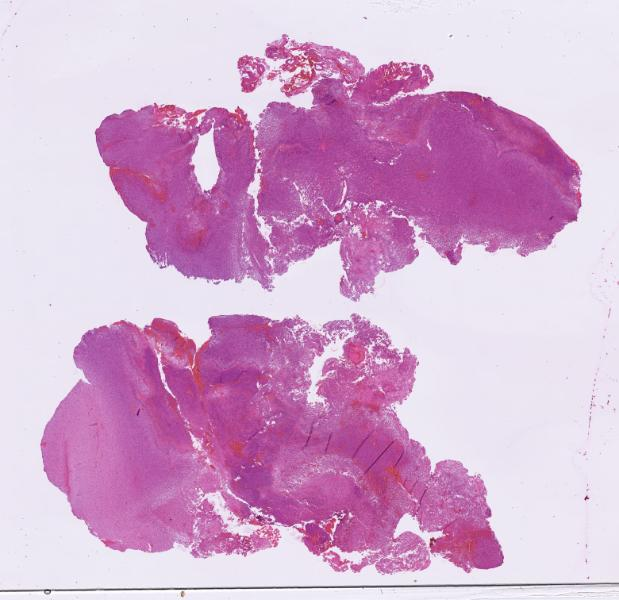
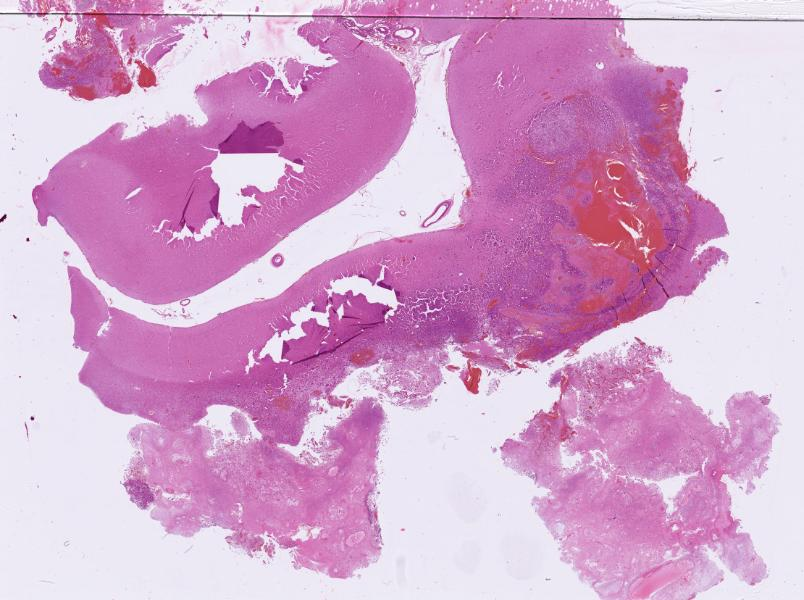
...
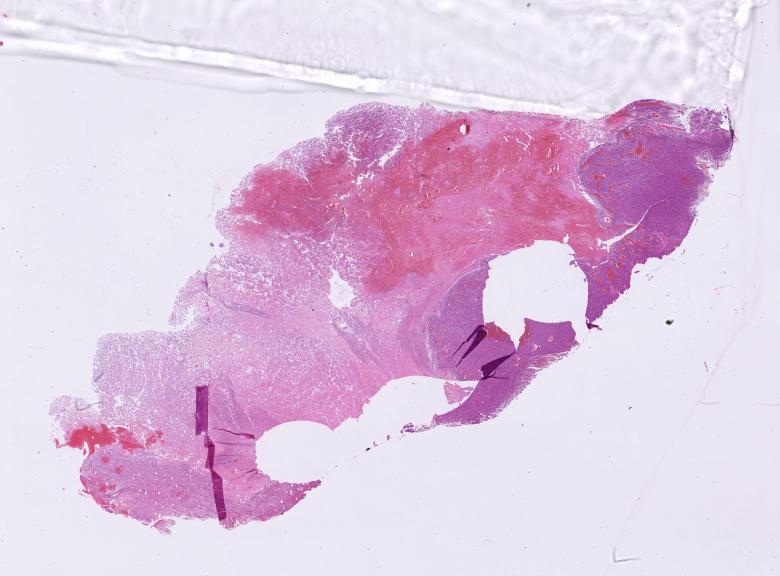
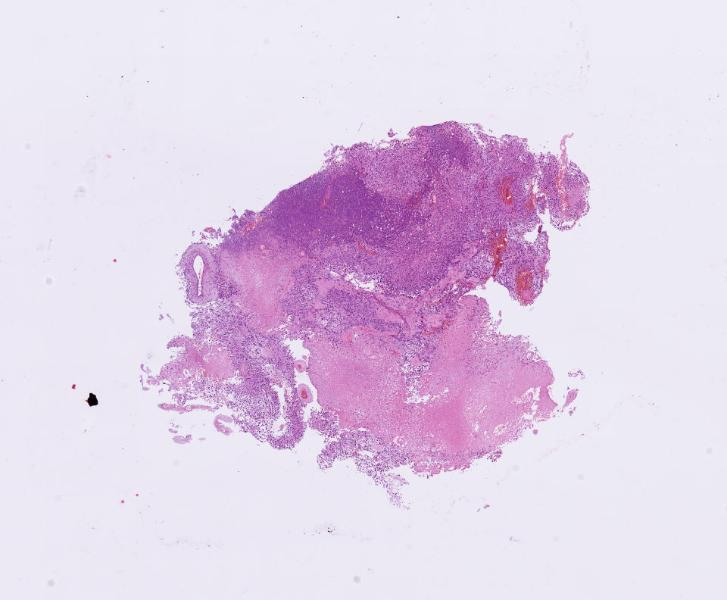
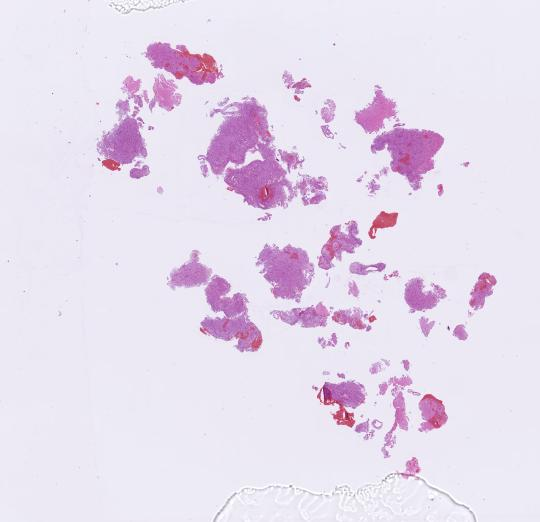
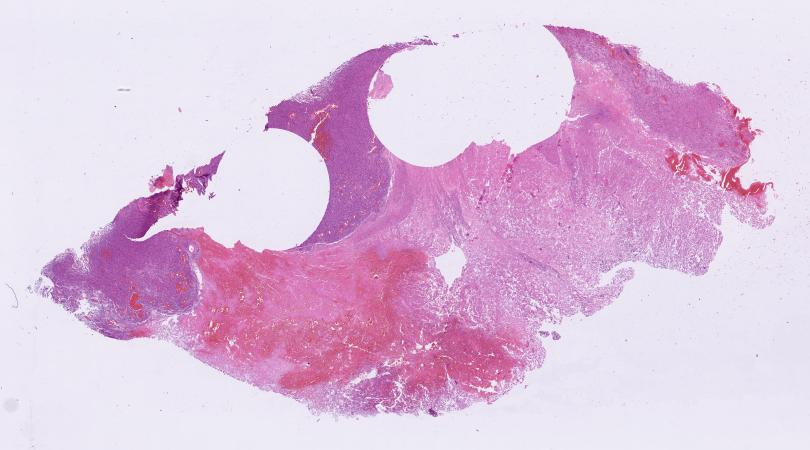
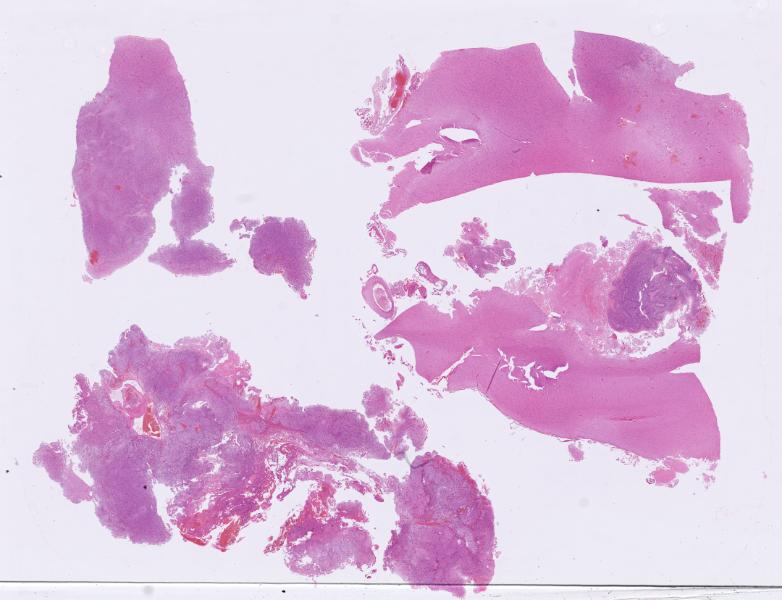

In [12]:
project.images

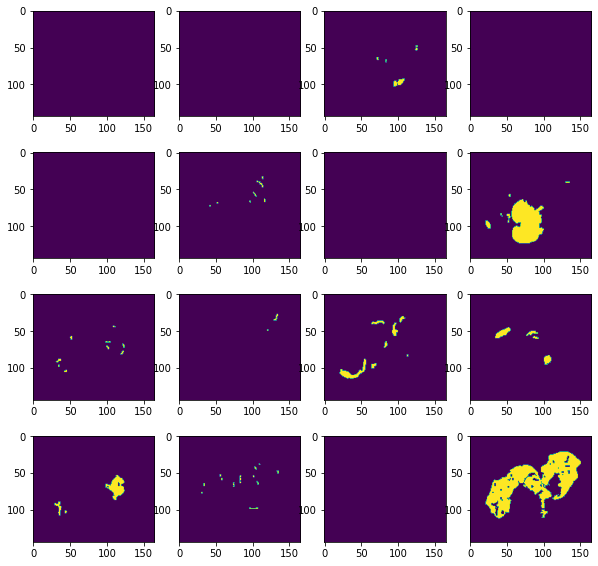

In [13]:
# NOTE: MOTHI shifts the given classes by one to the left. It caused me wasting too much time and I wanted to show it here
# You can see that tumor is in the first list in the upper list. 
# Also you can check the annotations of the B128-19_HE_Hamamatsu_40x.ndpi from the QuPath project
# But here, it is retrieved as the last element :/

arr = wsi.qupath_project.get_tile_annot_mask(18, (0, 0), (165, 144), 8, multichannel = True)

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(16):
    ax[i // 4][i % 4].imshow(arr[i])

In [14]:
patient = data.get_train_set()[0][0]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 3 # Class Blutung, since it is not multichannel, it is not shifted to the left

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

In [15]:
wsi.identifier

'B7-18'

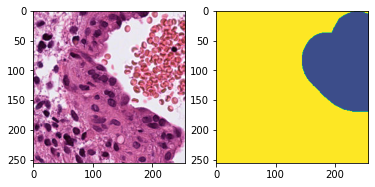

In [16]:
# Explicit example of we are getting the correct tiles

fig, axes = plt.subplots(1, 2)
axes[0].imshow(min_max_image(tiles_with_masks[0][0].get_image(wsi.image)))
axes[1].imshow(tiles_with_masks[0][1], vmin = 0, vmax = 17) # This tile has the unsure class, we will ignore it during training

In [17]:
patient = data.get_train_set()[0][2]
patient.load_wsis()
wsi = patient.get_wsis()[0][0]
wsi.load_wsi()

tiles_with_masks = []
label_index = 6 # Class Falten 

for tile in wsi.tiles[0]:
    annotation, _ = tile.get_annotation(wsi)
    if (annotation == label_index + 1).any():
        tiles_with_masks.append([tile, annotation])

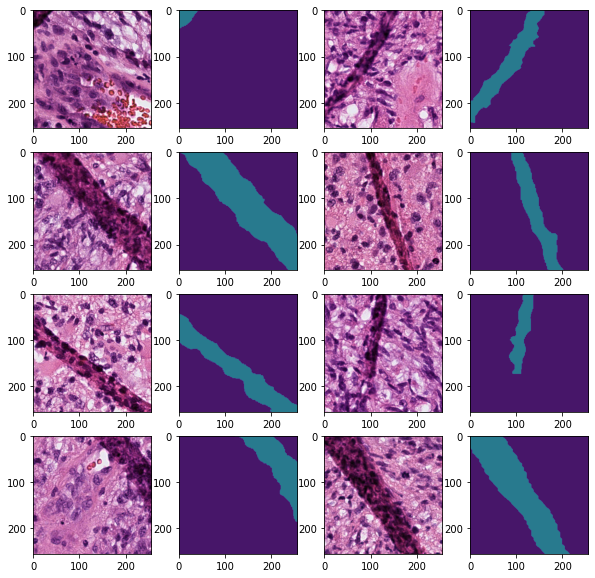

In [18]:
import random

fig, ax = plt.subplots(4, 4, figsize = (10, 10))
for i in range(4):
    tile1 = random.choice(tiles_with_masks)[0]
    tile2 = random.choice(tiles_with_masks)[0]
    ax[i][0].imshow(min_max_image(tile1.get_image(wsi.image)))
    ax[i][1].imshow(tile1.get_annotation(wsi)[0], vmin = 0, vmax = 17)
    ax[i][2].imshow(min_max_image(tile2.get_image(wsi.image)))
    ax[i][3].imshow(tile2.get_annotation(wsi)[0], vmin = 0, vmax = 17)

In [ ]:
from pathlib import Path
import os

def update_qupath_paths(qupath_project, file_folder_path, delete_not_found = False):
    uri2uri = {}
    images = os.listdir(file_folder_path)
    to_be_deleted = []
    for image in qupath_project.images:
        if image.image_name in images:
            old_path = image.uri
            new_path = "file:/" + os.path.join(file_folder_path, image.image_name).replace("\\", "/")
            uri2uri[old_path] = new_path
            print(f"Path of the {image.image_name} has been changed!")
        elif delete_not_found:
            to_be_deleted.append(image)
            print(f"{image.image_name} has been deleted!")
    qupath_project.update_image_paths(uri2uri = uri2uri)
    for image in to_be_deleted:
        qupath_project.remove_image(image)
    qupath_project.save()

In [2]:
from mothi.tiling_projects import QuPathTilingProject
EXAMPLE_PROJECT = r"C:\Users\PC\Downloads\QuPath-Annotations\project.qpproj"
qp_project = QuPathTilingProject(EXAMPLE_PROJECT, mode = "r+")

In [5]:
# WARNING DO NOT RUN THIS, IT UPDATES THE QUPATH PROJECT ACCORDING TO GIVEN FOLDER
# update_qupath_paths(qp_project, r"C:\Users\PC\Desktop\Fiverr\Max_Pathology\hamamatsu", delete_not_found = True)

Path of the B7-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B9-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B11-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B17-19_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B20-16_HE_Hamamatsu_40x.ndpi has been changed!
B23-18_HE_Hamamatsu_40x.ndpi has been deleted!
Path of the B27-19_HE_Hamamatsu_40x.ndpi has been changed!
B28-19_HE_Hamamatsu_40x.ndpi has been deleted!
Path of the B30-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B35-18_1_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B35-18_2_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B36-17_1_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B36-17_2_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B37-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B42-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B68-18_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B85-17_HE_Hamamatsu_40x.ndpi has been changed!
Path of the B10

In [ ]:
# Following parts will be updated since we changed our model's output channels and MOTHI setting is not multichannel

In [14]:
from datastructure import dataset_torch
import torch
import numpy as np

@torch.no_grad()
def infer_qupath(img_id, model, qupath_project, norm_function = None, level = 2, 
                 n_channels = 1, patch_size = 256, device = "cpu"):
    image = qupath_project.images[img_id]
    downsample, width, height = image.downsample_levels[level].values()
    max_width, max_height = image.width, image.height
    annotations = np.zeros((height, width, n_channels))
    tile_arr = []
    for x in range(0, width, patch_size):
        for y in range(0, height, patch_size):
            tile_width = min(patch_size, width - x)
            tile_height = min(patch_size, height - y)
            tile = qupath_project.get_tile(img_id, (x * (2 ** level), y * (2 ** level)), 
                                           size = (tile_width,
                                                   tile_height),
                                           downsample_level = level)
            tile_arr.append(tile)
            if norm_function:
                tile = norm_function(tile)
            tile_padded = np.zeros((patch_size, patch_size, tile.shape[2]), dtype = np.float32)
            tile_padded[:tile.shape[0], :tile.shape[1]] = tile
            tile_model_sample = torch.tensor(np.transpose(tile_padded[None], [0, 3, 1, 2]), dtype = torch.float).to(device)
            inter = model(tile_model_sample).cpu().numpy()
            logits = inter[0]
            annotations[y : y + tile_height, x : x + tile_width] = logits.argmax(axis = 0).astype(int)[:tile_height, :tile_width, None]
            tile_arr.append(tile_padded)
    return image, annotations, tile_arr

In [24]:
help(project)

Help on QuPathTilingProject in module mothi.tiling_projects object:

class QuPathTilingProject(paquo.projects.QuPathProject)
 |  QuPathTilingProject(path: Union[str, pathlib.Path], mode: Literal['r', 'r+', 'w', 'w+', 'a', 'a+', 'x', 'x+'] = 'r')
 |  
 |  load or create a new qupath project
 |  
 |  Parameters
 |  ----------
 |  path:
 |      path to `project.qpproj` file, or its parent directory
 |  mode:
 |      'r' --> readonly, error if not there 
 |  
 |      'r+' --> read/write, error if not there 
 |  
 |      'a' = 'a+' --> read/write, create if not there, append if there 
 |  
 |      'w' = 'w+' --> read/write, create if not there, truncate if there 
 |  
 |      'x' = 'x+' --> read/write, create if not there, error if there
 |  
 |  Method resolution order:
 |      QuPathTilingProject
 |      paquo.projects.QuPathProject
 |      builtins.object
 |  
 |  Methods defined here:
 |  
 |  __init__(self, path: Union[str, pathlib.Path], mode: Literal['r', 'r+', 'w', 'w+', 'a', 'a+', 

In [20]:
tile = project.get_tile(14, (x * (2 ** level), y * (2 ** level)), 
                                           size = (tile_width,
                                                   tile_height),
                                           downsample_level = level)

NameError: name 'qupath_project' is not defined

In [6]:
# Please Ignore This Part. We can load the model and visualize our models predictions using the upper function
# If you have any pretrained model, you can test the if our function is working correctly
# I will test it using a pretrained model

from models import unet

import torch

#device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device = "cpu"
torch.cuda.empty_cache()
model = unet.UNet(3,
                      17,
                      5,
                      6,
                      True,
                      True,
                      'upconv')

model.to(device)

UNet(
  (down_path): ModuleList(
    (0): UNetConvBlock(
      (block): Sequential(
        (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): ReLU()
        (2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): ReLU()
        (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (1): UNetConvBlock(
      (block): Sequential(
        (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): ReLU()
        (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (4): ReLU()
        (5): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): UNetConv

In [7]:
model.load_state_dict(torch.load(r"C:\Users\PC\Downloads\model_best_1.47"))

<All keys matched successfully>

In [15]:
image, ann, tile_arr = infer_qupath(14, model, project, level = 5, norm_function = dataset_torch.PathologyDataset.colormatch)

NameError: name 'project' is not defined

In [18]:
tile = project.get_tile(14, (0, 0), 
                                           size = (1500,
                                                   1584),
                                           downsample_level = 5)

C:\Users\PC\AppData\Local\Programs\Python\Python39\lib\site-packages\tiffslide\tiffslide.py:750: UserWarning: hamamatsu-format metadata parsing only partially implemented!
  return getattr(self, f"parse_{fmt}")()  # type: ignore


In [28]:
a = model(torch.tensor(np.transpose(dataset_torch.PathologyDataset.colormatch(tile), [2, 0, 1])[None]).float())

ImageEntries(['B7-18_HE_Hamamatsu_40x.ndpi', 'B9-18_HE_Hamamatsu_40x.ndpi', 'B11-18_HE_Hamamatsu_40x.ndpi', 'B17-19_HE_Hamamatsu_40x.ndpi', 'B20-16_HE_Hamamatsu_40x.ndpi', 'B27-19_HE_Hamamatsu_40x.ndpi', 'B30-18_HE_Hamamatsu_40x.ndpi', 'B35-18_1_HE_Hamamatsu_40x.ndpi', 'B35-18_2_HE_Hamamatsu_40x.ndpi', 'B36-17_1_HE_Hamamatsu_40x.ndpi', 'B36-17_2_HE_Hamamatsu_40x.ndpi', 'B37-17_HE_Hamamatsu_40x.ndpi', 'B42-17_HE_Hamamatsu_40x.ndpi', 'B68-18_HE_Hamamatsu_40x.ndpi', 'B85-17_HE_Hamamatsu_40x.ndpi', 'B100-17_HE_Hamamatsu_40x.ndpi', 'B115-17_HE_Hamamatsu_40x.ndpi', 'B127-19_HE_Hamamatsu_40x.ndpi', 'B128-19_HE_Hamamatsu_40x.ndpi', 'B129-19_HE_Hamamatsu_40x.ndpi', 'B132-17_HE_Hamamatsu_40x.ndpi', 'B138-18_HE_Hamamatsu_40x.ndpi', 'B149-16_HE_Hamamatsu_40x.ndpi', 'B157-17_HE_Hamamatsu_40x.ndpi', 'B162-17_HE_Hamamatsu_40x.ndpi', 'B165-19_HE_Hamamatsu_40x.ndpi', 'B177-18_HE_Hamamatsu_40x.ndpi', 'B178-19_HE_Hamamatsu_40x.ndpi', 'B179-17_HE_Hamamatsu_40x.ndpi', 'B181-16_HE_Hamamatsu_40x.ndpi', 'B187-16_HE_Hamamatsu_40x.ndpi', 'B201-18_HE_Hamamatsu_40x.ndpi', 'B205-09_HE_Hamamatsu_40x.ndpi', 'B205-18_1_HE_Hamamatsu_40x.ndpi', 'B205-18_2_HE_Hamamatsu_40x.ndpi', 'B205-18_HE_Hamamatsu_40x.ndpi', 'B23-18_HE_Hamamatsu_40x-006.ndpi'])
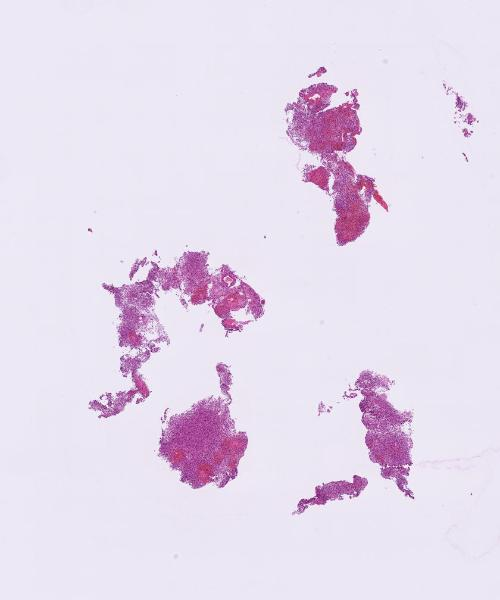
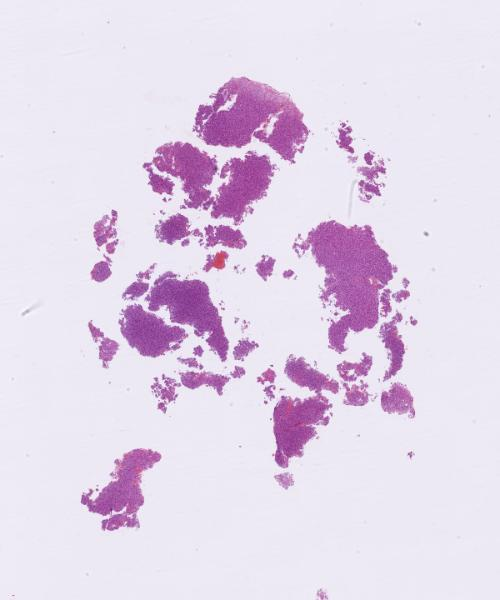
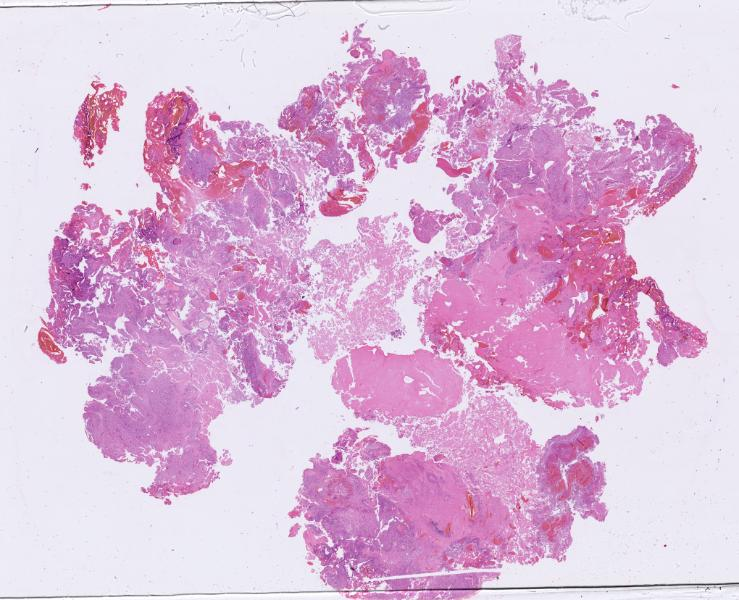
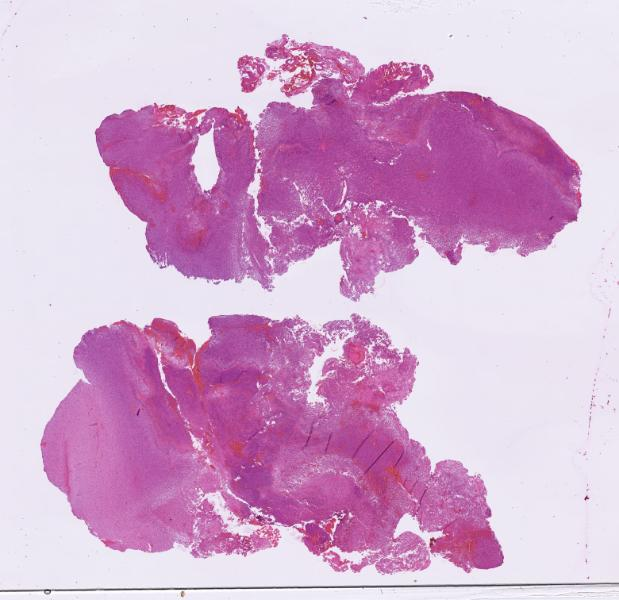
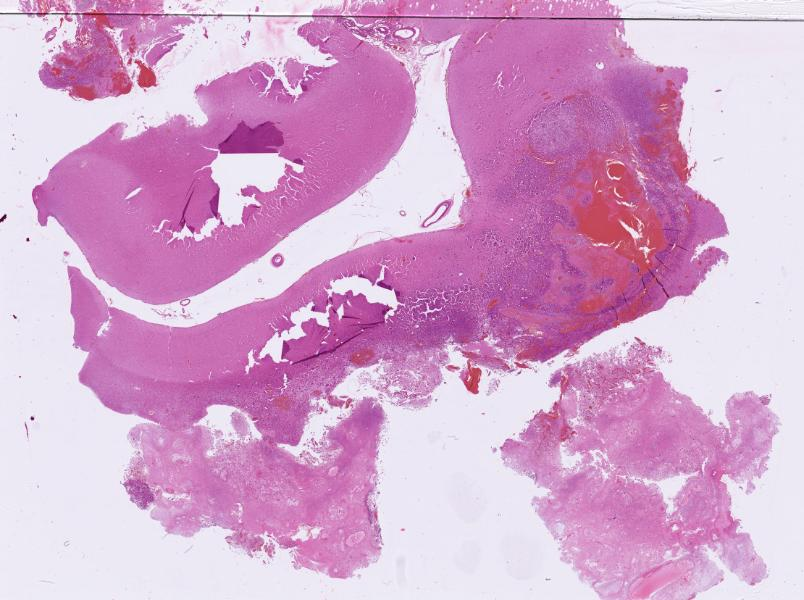
...
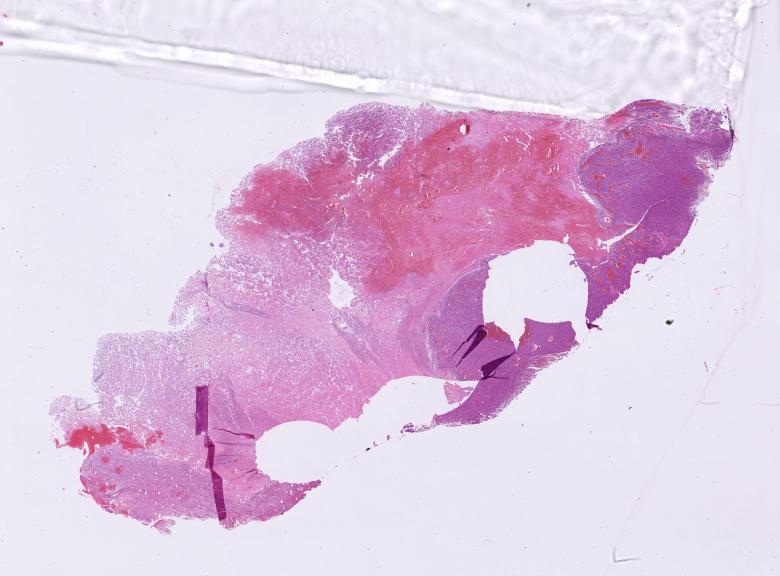
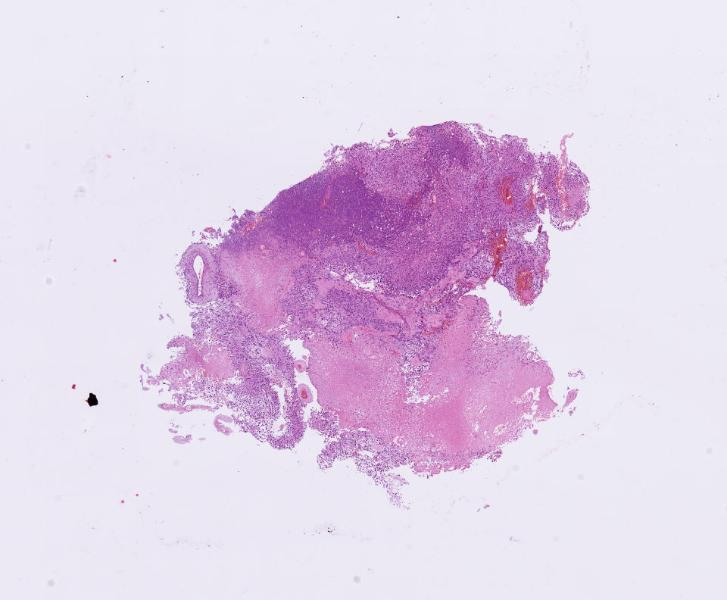
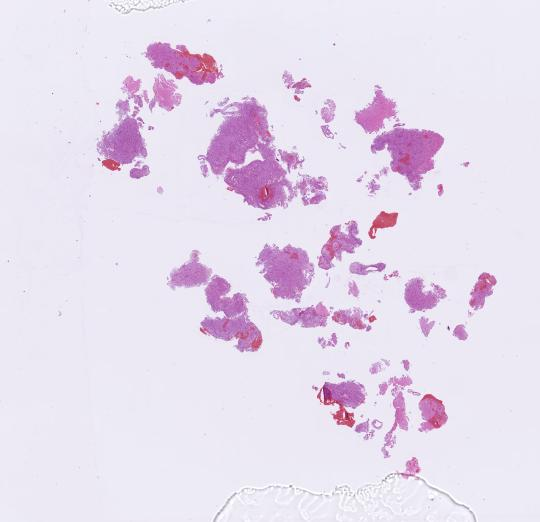
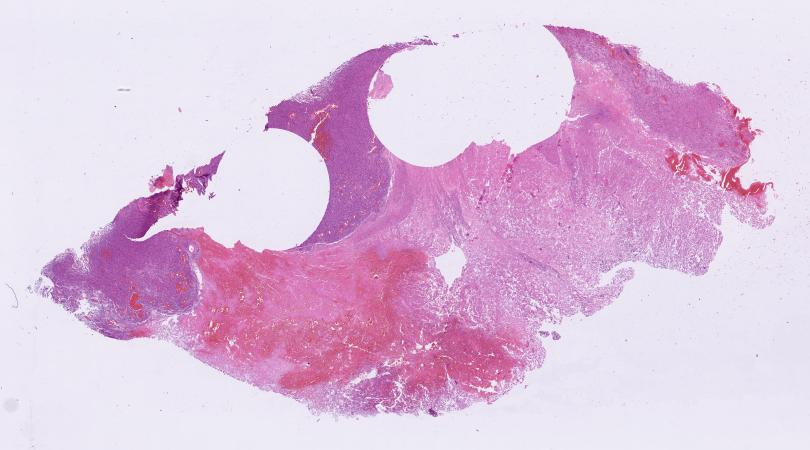
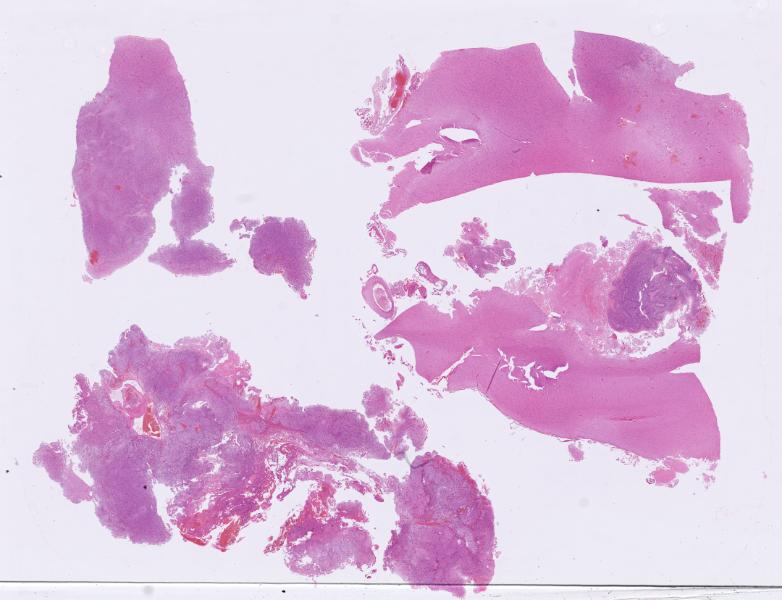

In [46]:
project.images

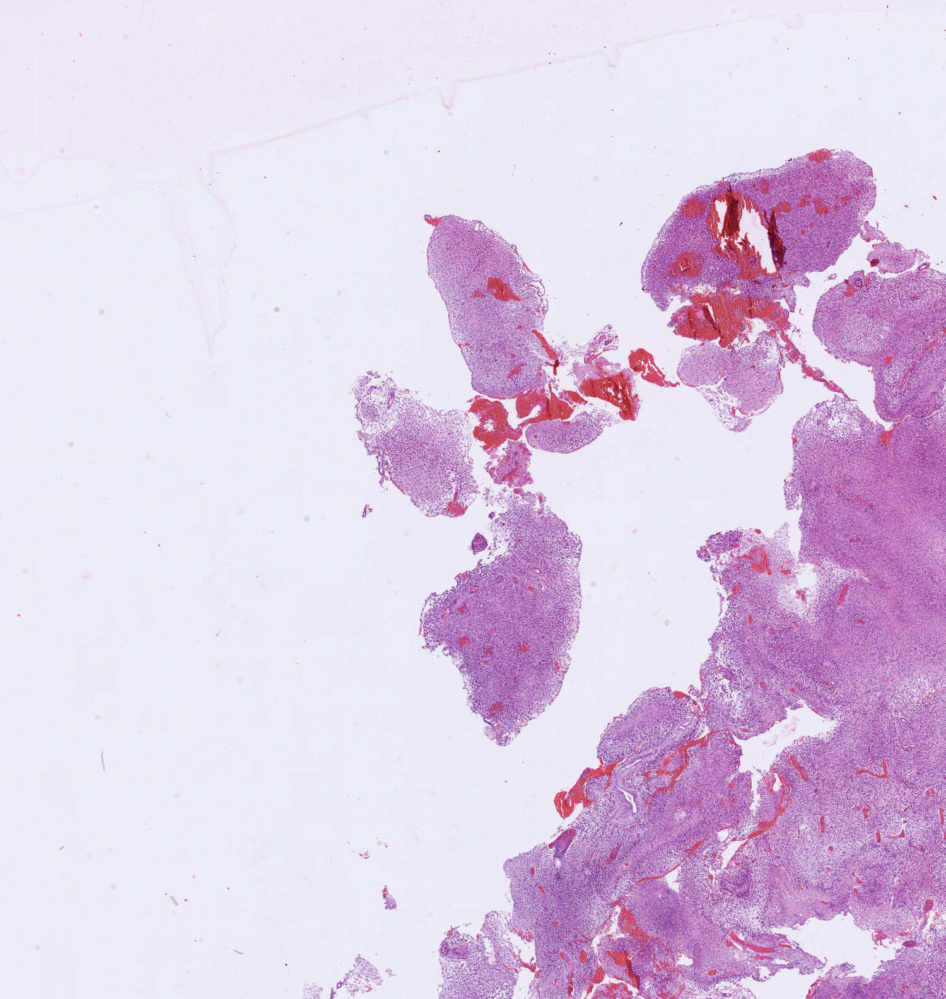

In [47]:
tile

In [31]:
np.unique(a.argmax(axis = 1)[0])

array([ 0,  1,  2,  3,  4,  7,  9, 10, 11, 12, 13, 14, 15], dtype=int64)

In [8]:
from datastructure import dataset_torch

import importlib
importlib.reload(dataset_torch)

dataset = dataset_torch.PathologyDataset(data.get_validation_set(), infer = True)

In [63]:
a = model(torch.tensor(dataset[1][0])[None])

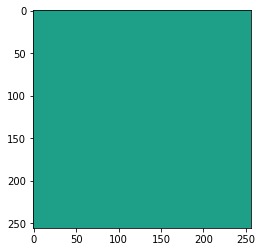

In [65]:
plt.imshow(dataset[1][1], vmin=0, vmax = 16)

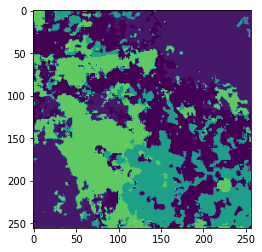

In [64]:
plt.imshow(a.detach().numpy()[0].argmax(axis = 0), vmin = 0, vmax = 16)

In [24]:
dataset.classes

['Tumor',
 'Hirnparenchym',
 'Infiltrationszone',
 'Blutung',
 'Luftblasen',
 'Haare',
 'Falten',
 'Risse',
 'Nekrosen',
 'Pseudopalisaden',
 'Artefakt',
 'artifiziell verändertes Gewebe',
 'Nekrose und Blutung',
 'Pränekrose',
 'out of focus',
 'Filzstift']

In [5]:
import random

# tumor are in tiles / total area
m = 0
for i in range(1000):
    m += dataset[random.randint(0, 11669)][1].mean()
print(m / 1000)

0.43557037353515626


In [49]:
device = "cpu"

In [10]:
# This cell infers dataset, will be a function

batch_size = 8
save_dir = r"C:\Users\PC\Desktop\infer_test"
patch_size = 256
device = "cuda"

a = torch.utils.data.DataLoader(dataset, pin_memory = True, batch_size = batch_size)

b = 0
c = 0
n_channels = 1

model = model.to(device)
ann_mask = None

with torch.no_grad():
    for tiles, size, level, identifier, position in a:
        if ann_mask is None:
            ann_mask = np.zeros((size[0][0], size[1][0]), dtype = np.uint8)
            current_level = level[0]
            current_identifier = identifier[0]
            current_size = (size[0][0], size[1][0])
        tiles = tiles.to(device)
        pred = model(tiles).detach().cpu().numpy()
        pred_map = pred.sum(axis = (2, 3)).argmax(axis = 1).astype(np.uint8)
        for i in range(batch_size):
            if identifier[i] != current_identifier:
                np.save(f"{current_identifier}_{current_level}.npy", ann_mask)
                current_level = level[i]
                current_identifier = identifier[i]
                current_size = (size[0][i], size[1][i])
                ann_mask = np.zeros((size[0][i], size[1][i]), dtype = np.uint8)
                break
            pos_x = position[0][i]
            width = min(patch_size, current_size[0] - pos_x)
            pos_y = position[1][i]
            height = min(patch_size, current_size[1] - pos_y)
            # ann_mask[pos_x : pos_x + width, pos_y : pos_y + height] = np.transpose(pred_map[i], [1, 0])[:width, :height]
            ann_mask[pos_x : pos_x + width, pos_y : pos_y + height] = pred_map[i]
        print(c)
        c += 1

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

Exception ignored in: <function _OpenSlide.__del__ at 0x0000026D72C5F040>
Traceback (most recent call last):
  File "C:\Users\PC\AppData\Local\Programs\Python\Python39\lib\site-packages\openslide\lowlevel.py", line 124, in __del__
    self._close(self)
  File "C:\Users\PC\AppData\Local\Programs\Python\Python39\lib\site-packages\openslide\lowlevel.py", line 204, in _check_close
    def _check_close(_result, _func, args):
KeyboardInterrupt: 


745
746
747
748
749
750
751
752
753
754
755
756
757
758
759
760
761


KeyboardInterrupt: 

In [12]:
# This cell infers dataset, will be a function

batch_size = 8
save_dir = r"C:\Users\PC\Desktop\infer_test"
patch_size = 256
device = "cuda"

a = torch.utils.data.DataLoader(dataset, pin_memory = True, batch_size = batch_size)

b = 0
c = 0
n_channels = 1

model = model.to(device)
ann_mask = None

with torch.no_grad():
    for tiles, size, level, identifier, position in a:
        if ann_mask is None:
            ann_mask = np.zeros((size[0][0], size[1][0]), dtype = np.uint8)
            current_level = level[0]
            current_identifier = identifier[0]
            current_size = (size[0][0], size[1][0])
        tiles = tiles.to(device)
        pred = model(tiles).detach().cpu().numpy()
        pred_map = gaussian_filter(pred, 1, axes = (2, 3)).argmax(axis = 1).astype(np.uint8)
        for i in range(batch_size):
            if identifier[i] != current_identifier:
                np.save(f"{current_identifier}_{current_level}.npy", ann_mask)
                current_level = level[i]
                current_identifier = identifier[i]
                current_size = (size[0][i], size[1][i])
                ann_mask = np.zeros((size[0][i], size[1][i]), dtype = np.uint8)
                break
            pos_x = position[0][i]
            width = min(patch_size, current_size[0] - pos_x)
            pos_y = position[1][i]
            height = min(patch_size, current_size[1] - pos_y)
            ann_mask[pos_x : pos_x + width, pos_y : pos_y + height] = np.transpose(pred_map[i], [1, 0])[:width, :height]
            # ann_mask[pos_x : pos_x + width, pos_y : pos_y + height] = pred_map[i]
        print(c)
        c += 1

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

KeyboardInterrupt: 

In [1]:
from scipy.ndimage import gaussian_filter
import numpy as np


gaussian_filter(np.zeros((1, 2)), 1, axes = (0, 1))

array([[0., 0.]])

In [86]:
help(gaussian_filter)

Help on function gaussian_filter in module scipy.ndimage._filters:

gaussian_filter(input, sigma, order=0, output=None, mode='reflect', cval=0.0, truncate=4.0)
    Multidimensional Gaussian filter.
    
    Parameters
    ----------
    input : array_like
        The input array.
    sigma : scalar or sequence of scalars
        Standard deviation for Gaussian kernel. The standard
        deviations of the Gaussian filter are given for each axis as a
        sequence, or as a single number, in which case it is equal for
        all axes.
    order : int or sequence of ints, optional
        The order of the filter along each axis is given as a sequence
        of integers, or as a single number. An order of 0 corresponds
        to convolution with a Gaussian kernel. A positive order
        corresponds to convolution with that derivative of a Gaussian.
    output : array or dtype, optional
        The array in which to place the output, or the dtype of the
        returned array. By d

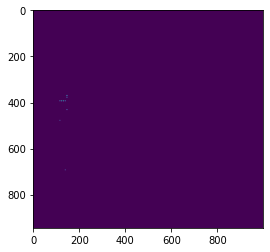

In [79]:
# I aborted previous cell since I was running it on the cpu
# Yet you can see that we were infering only the tiles
# No weights are loaded, hence it is random
plt.imshow(ann_mask[::100, ::100].T == 1)

In [ ]:
np.unique(ann_mask)

In [1]:
from scipy import ndimage

result = ndimage.median_filter(ann_mask[::10, ::10], size=20)

NameError: name 'ann_mask' is not defined

(-0.5, 998.5, 944.5, -0.5)

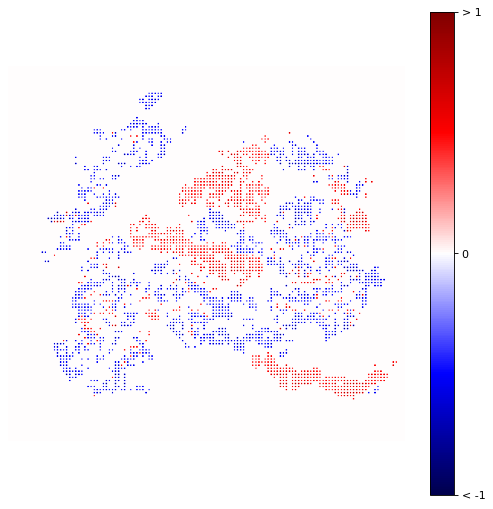

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 8), dpi=80)
cax = plt.imshow((ann_mask[::100, ::100].T == 9) * -1 + (ann_mask[::100, ::100].T == 1) * 1, cmap = "seismic", vmin = -1, vmax = 1)
cbar = plt.colorbar(cax, ticks = [-1, 0, 1])
cbar.ax.set_yticklabels(['< -1', '0', '> 1'])  # vertically oriented colorbar
plt.axis('off')
#plt.savefig("B132-17_tumor_nekrose_segmentation_sum_first")

In [50]:
np.unique(ann_mask.T[::50, ::50])

array([ 0,  1,  9, 12, 13], dtype=uint8)

In [109]:
def plot_infer(ann_mask, qupath_project, save_path):
    classes = ["Background"] + list(qupath_project._inverse_class_dict.keys())[:-1] #Ignore unsure class
    my_cmap = [(1., 1., 1.)] + [np.array(i.color.to_rgb()) / 255 for i in list(qupath_project._class_dict.values())[:-1]]
    cmap = mpl.colors.ListedColormap(my_cmap)
    ratio_x = ann_mask.shape[0] / (ann_mask.shape[0] + ann_mask.shape[1])
    ratio_y = ann_mask.shape[1] / (ann_mask.shape[0] + ann_mask.shape[1])
    plt.figure(figsize=(int(32 * ratio_x * 2), int(32 * ratio_y * 2)), dpi=320)
    cax = plt.imshow(ann_mask.T[::50, ::50], cmap = cmap, vmin = 0, vmax = 16)
    cbar = plt.colorbar(cax, ticks = range(0, 17))
    cbar.ax.set_yticklabels(classes)  # vertically oriented colorbar
    plt.axis('off')
    plt.savefig(save_path, facecolor = "white")

In [110]:
plot_infer(ann_mask, project, r"C:\Users\PC\Desktop\Test.png")

In [104]:
ann_mask[::50, ::50].shape

(1997, 1890)

In [94]:
import matplotlib as mpl

my_cmap = [(1., 1., 1.)] + [np.array(i.color.to_rgb()) / 255 for i in list(project._class_dict.values())[:-1]]

cmap = mpl.colors.ListedColormap(my_cmap)

In [96]:
project.

(99840, 94464)

In [97]:
99840 / 94464

1.056910569105691

In [99]:
import matplotlib.pyplot as plt

plt.figure(figsize=(32, 32), dpi=320)
cax = plt.imshow(ann_mask.T[::50, ::50], cmap = cmap, vmin = 0, vmax = 16)
cbar = plt.colorbar(cax, ticks = range(0, 17))
cbar.ax.set_yticklabels(["Background"] + dataset.classes)  # vertically oriented colorbar
plt.axis('off')
plt.savefig("B132-17_test", facecolor = "white")

In [30]:
dataset.classes

['Tumor',
 'Hirnparenchym',
 'Infiltrationszone',
 'Blutung',
 'Luftblasen',
 'Haare',
 'Falten',
 'Risse',
 'Nekrosen',
 'Pseudopalisaden',
 'Artefakt',
 'artifiziell verändertes Gewebe',
 'Nekrose und Blutung',
 'Pränekrose',
 'out of focus',
 'Filzstift']

In [76]:
((ann_mask[::100, ::100].T == 9) * -1 + (ann_mask[::100, ::100].T == 1) * 1).shape

(945, 999)

In [68]:
ann_mask.min()

0

In [38]:
import numpy as np

ann_mask =  np.load("B132-17_2.npy")

In [10]:
mode([0, 0, 1, 1, 1], axis = None)[0]

C:\Users\PC\AppData\Local\Temp\ipykernel_23324\3927808560.py:1: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode([0, 0, 1, 1, 1], axis = None)[0]


array([1])

In [21]:
ann_mask.shape

(99840, 94464)

In [107]:
from scipy.stats import mode as mode

def edit(arr, k = 19):
    for x in range(0, arr.shape[0], k):
        for y in range(0, arr.shape[1], k):
            arr[x:x+k, y:y+k] = arr[x:x+k, y:y+k].max()
    return arr
            
ann_mask_b = edit(ann_mask[::100, ::100], 3)

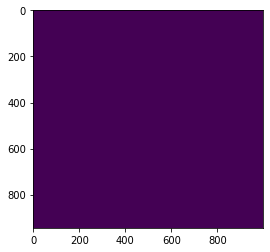

In [100]:
import matplotlib.pyplot as plt
plt.imshow(ann_mask_b.T == 1)

In [5]:
def edit(arr, k = 5):
    for x in range(0, arr.shape[0], k):
        for y in range(0, arr.shape[1], k):
            arr[x:x+k, y:y+k] = 

NameError: name 'dataset' is not defined

In [ ]:
#!/usr/bin/env python3

import numpy as np
from PIL import Image
from scipy.ndimage import generic_filter
from scipy import stats

# Modal filter
def modal(P):
    """We receive P[0]..P[8] with the pixels in the 3x3 surrounding window"""
    mode = stats.mode(P)
    return mode.mode[0]

im = ann_mask[::50, ::50].T == 1

# Run modal filter
result = generic_filter(im, modal, (3, 3))

# Save result or use OpenCV 'imwrite()'
# Image.fromarray(result).save('result.png')

C:\Users\PC\AppData\Local\Temp\ipykernel_23692\1985322243.py:11: FutureWarning: Unlike other reduction functions (e.g. `skew`, `kurtosis`), the default behavior of `mode` typically preserves the axis it acts along. In SciPy 1.11.0, this behavior will change: the default value of `keepdims` will become False, the `axis` over which the statistic is taken will be eliminated, and the value None will no longer be accepted. Set `keepdims` to True or False to avoid this warning.
  mode = stats.mode(P)


ImageEntries(['B7-18_HE_Hamamatsu_40x.ndpi', 'B9-18_HE_Hamamatsu_40x.ndpi', 'B11-18_HE_Hamamatsu_40x.ndpi', 'B17-19_HE_Hamamatsu_40x.ndpi', 'B20-16_HE_Hamamatsu_40x.ndpi', 'B27-19_HE_Hamamatsu_40x.ndpi', 'B30-18_HE_Hamamatsu_40x.ndpi', 'B35-18_1_HE_Hamamatsu_40x.ndpi', 'B35-18_2_HE_Hamamatsu_40x.ndpi', 'B36-17_1_HE_Hamamatsu_40x.ndpi', 'B36-17_2_HE_Hamamatsu_40x.ndpi', 'B37-17_HE_Hamamatsu_40x.ndpi', 'B42-17_HE_Hamamatsu_40x.ndpi', 'B68-18_HE_Hamamatsu_40x.ndpi', 'B85-17_HE_Hamamatsu_40x.ndpi', 'B100-17_HE_Hamamatsu_40x.ndpi', 'B115-17_HE_Hamamatsu_40x.ndpi', 'B127-19_HE_Hamamatsu_40x.ndpi', 'B128-19_HE_Hamamatsu_40x.ndpi', 'B129-19_HE_Hamamatsu_40x.ndpi', 'B132-17_HE_Hamamatsu_40x.ndpi', 'B138-18_HE_Hamamatsu_40x.ndpi', 'B149-16_HE_Hamamatsu_40x.ndpi', 'B157-17_HE_Hamamatsu_40x.ndpi', 'B162-17_HE_Hamamatsu_40x.ndpi', 'B165-19_HE_Hamamatsu_40x.ndpi', 'B177-18_HE_Hamamatsu_40x.ndpi', 'B178-19_HE_Hamamatsu_40x.ndpi', 'B179-17_HE_Hamamatsu_40x.ndpi', 'B181-16_HE_Hamamatsu_40x.ndpi', 'B187-16_HE_Hamamatsu_40x.ndpi', 'B201-18_HE_Hamamatsu_40x.ndpi', 'B205-09_HE_Hamamatsu_40x.ndpi', 'B205-18_1_HE_Hamamatsu_40x.ndpi', 'B205-18_2_HE_Hamamatsu_40x.ndpi', 'B205-18_HE_Hamamatsu_40x.ndpi', 'B23-18_HE_Hamamatsu_40x-006.ndpi'])
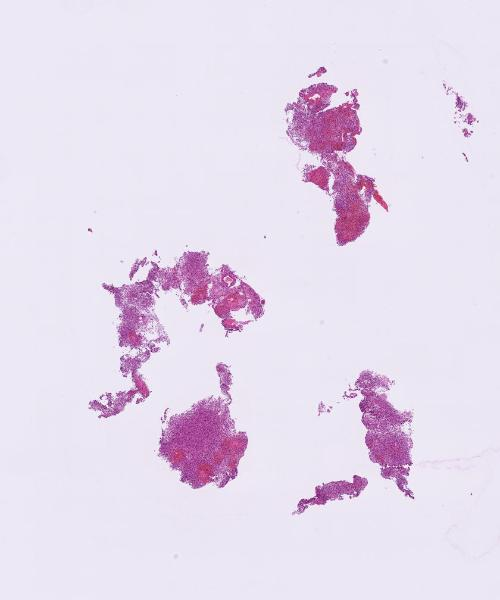
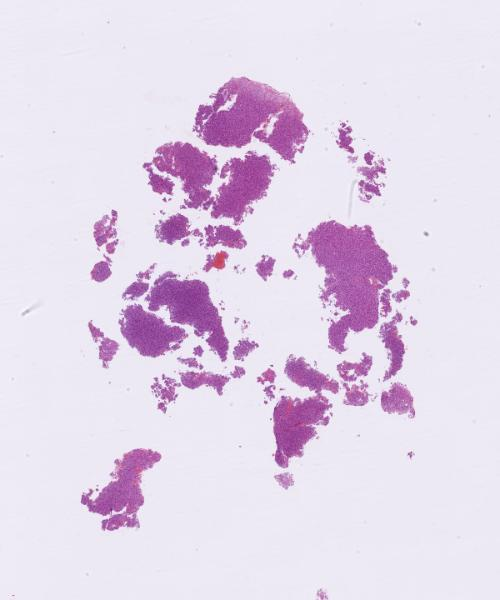
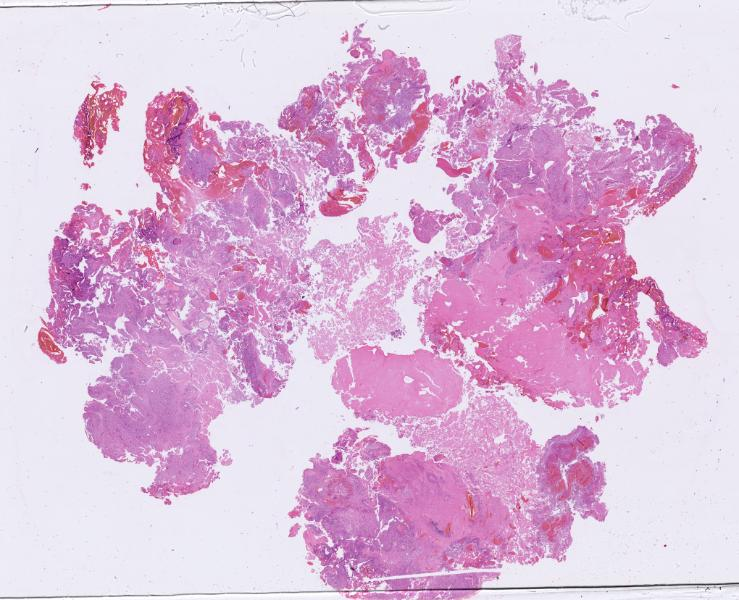
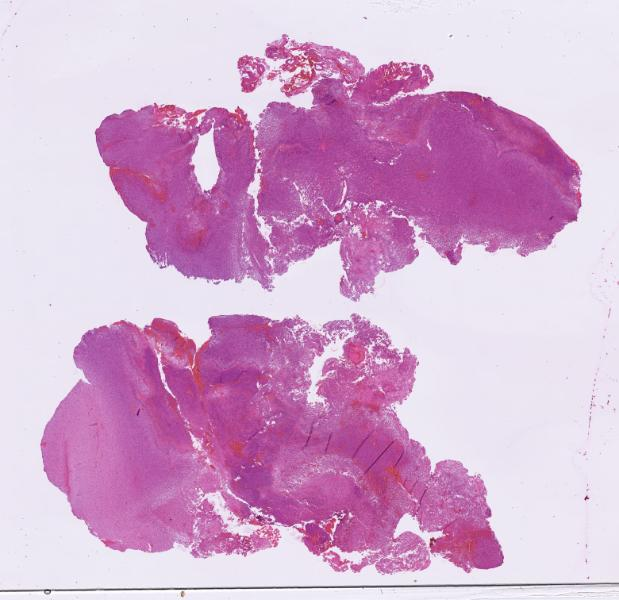
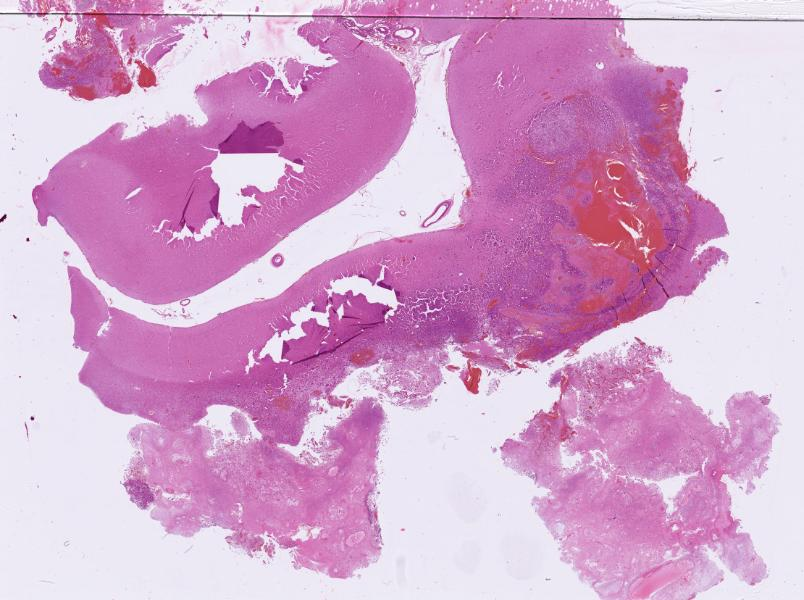
...
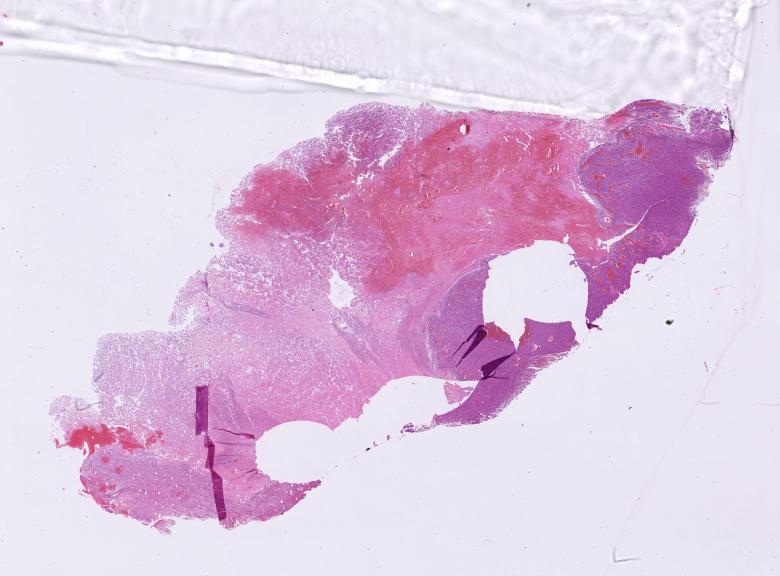
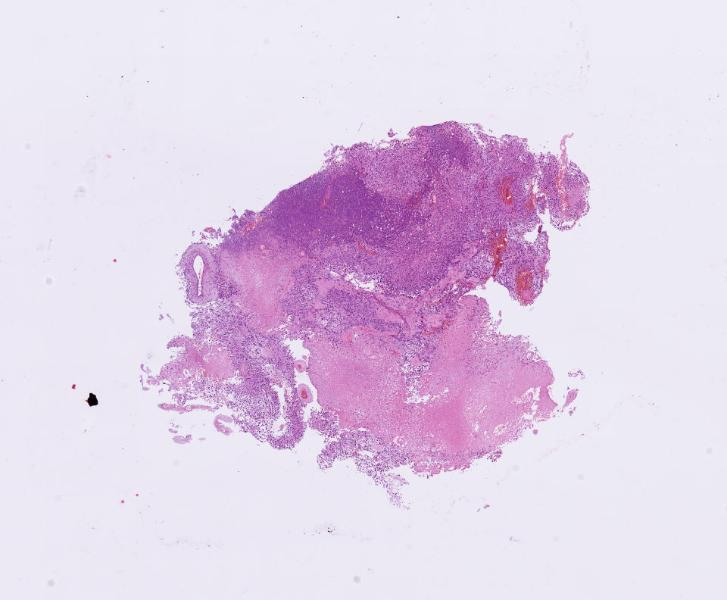
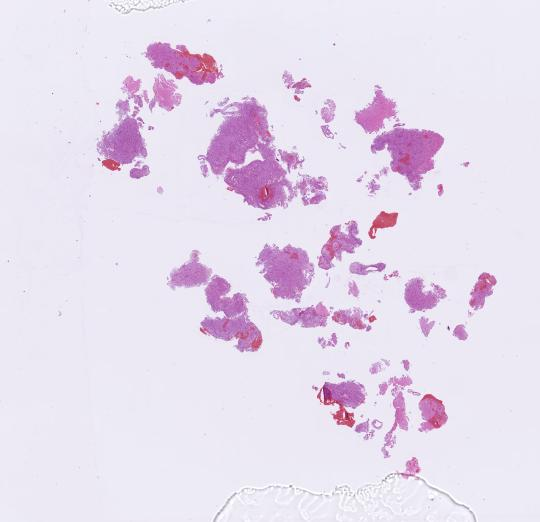
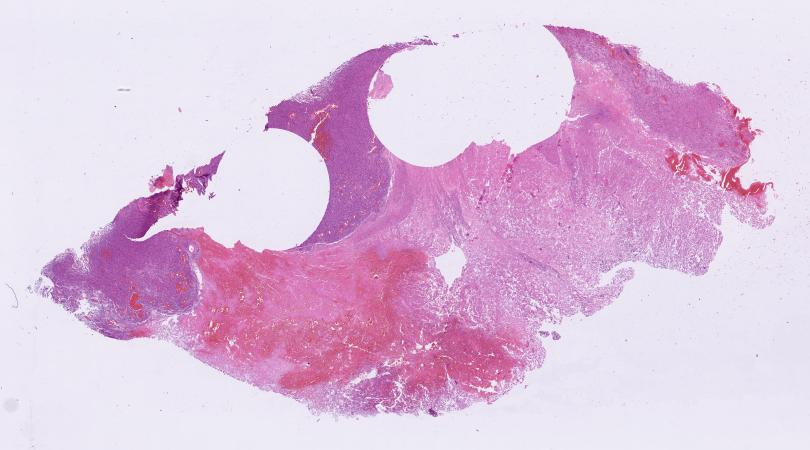
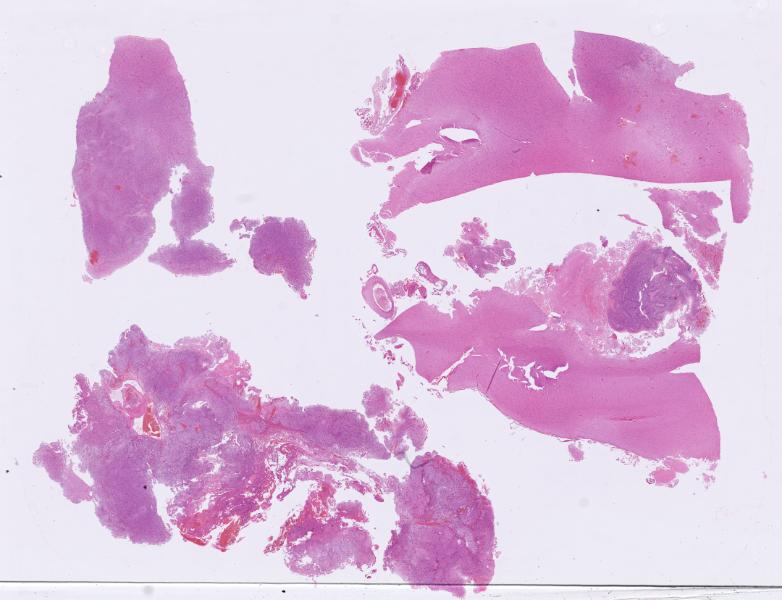

In [10]:
project.images